In [3]:
%pip install kagglehub

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('home-credit-default-risk')

print("Path to competition files:", path)

Path to competition files: /Users/xts/.cache/kagglehub/competitions/home-credit-default-risk


/Users/xts/.pyenv/versions/3.12.10/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load datasets from the Kaggle download directory
data_dir = Path(path)

train = pd.read_csv(data_dir / "application_train.csv")
test = pd.read_csv(data_dir / "application_test.csv")

# Display dataset dimensions
print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

# Preview the first five rows
display(train.head())


Training dataset shape: (307511, 122)
Test dataset shape: (48744, 121)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Target counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target proportions:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


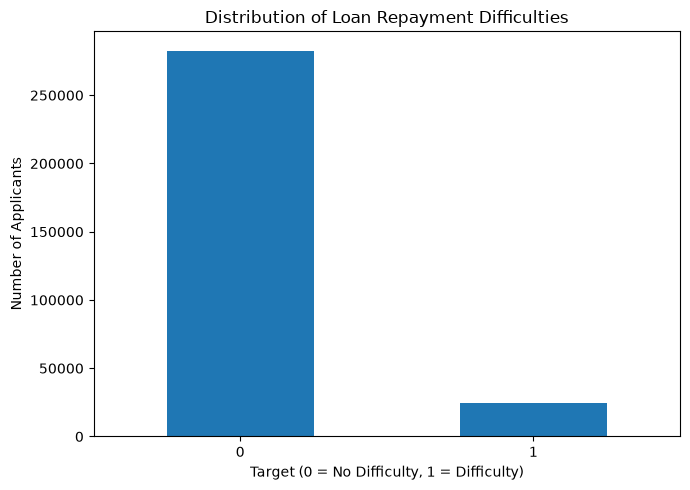

In [6]:

# Count observations in each target class
target_counts = train["TARGET"].value_counts().sort_index()

# Calculate class proportions
target_proportions = train["TARGET"].value_counts(
    normalize=True
).sort_index()

print("Target counts:")
print(target_counts)

print("\nTarget proportions:")
print(target_proportions)

# Visualize target distribution
plt.figure(figsize=(7, 5))

target_counts.plot(kind="bar")

plt.title("Distribution of Loan Repayment Difficulties")
plt.xlabel("Target (0 = No Difficulty, 1 = Difficulty)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


In [7]:

# Calculate missing value counts and percentages
missing_count = train.isnull().sum()

missing_percentage = (
    train.isnull().mean() * 100
)

# Create a missing value summary
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Sort features by missing percentage
missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

# Display the top 20 features with missing values
display(missing_summary.head(20))


,Missing Count,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


In [8]:

# Identify numerical and categorical features
numerical_features = train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Exclude target and applicant ID from predictors
numerical_features = [
    col for col in numerical_features
    if col not in ["TARGET", "SK_ID_CURR"]
]

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)


Number of numerical features: 104
Number of categorical features: 16

Categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


/var/folders/0t/2n1_cc3d4p73yldrk2b50t240000gn/T/ipykernel_88262/976344853.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train.select_dtypes(


In [9]:

%pip install scikit-learn


Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:

from sklearn.model_selection import train_test_split

# Separate predictors and target variable
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
y = train["TARGET"]

# Split data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset dimensions
print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_valid.value_counts(normalize=True))


X_train shape: (246008, 120)
X_valid shape: (61503, 120)

Training target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Validation target distribution:
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create a preprocessing pipeline for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create a preprocessing pipeline for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Preprocessing pipeline created successfully!")


Numerical features: 104
Categorical features: 16
Preprocessing pipeline created successfully!


In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
import time

# Create the logistic regression pipeline
logistic_model = Pipeline(steps=[
      ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

# Train the baseline model
start_time = time.time()

logistic_model.fit(X_train, y_train)

training_time = time.time() - start_time

# Predict probabilities for the positive class
logistic_probs = logistic_model.predict_proba(X_valid)[:, 1]

# Calculate validation ROC-AUC
logistic_auc = roc_auc_score(y_valid, logistic_probs)

print(f"Training time: {training_time:.2f} seconds")
print(f"Logistic Regression Validation AUC: {logistic_auc:.4f}")


Training time: 7.48 seconds
Logistic Regression Validation AUC: 0.7483


In [13]:

%pip install lightgbm


Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:

import lightgbm as lgb
import time

# Create separate copies for LightGBM
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

# Convert categorical columns to pandas category dtype
for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")

    X_valid_lgb[col] = pd.Categorical(
        X_valid_lgb[col],
        categories=X_train_lgb[col].cat.categories
    )

print("Training data shape:", X_train_lgb.shape)
print("Validation data shape:", X_valid_lgb.shape)
print("LightGBM data preparation completed!")


Training data shape: (246008, 120)
Validation data shape: (61503, 120)
LightGBM data preparation completed!


In [15]:

from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import time

# Initialize the LightGBM classifier
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

# Train the model with early stopping
start_time = time.time()

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_valid_lgb, y_valid)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=False
        )
    ]
)

lgb_training_time = time.time() - start_time

# Predict probabilities on the validation set
lgb_probs = lgb_model.predict_proba(X_valid_lgb)[:, 1]

# Calculate validation ROC-AUC
lgb_auc = roc_auc_score(y_valid, lgb_probs)

print(f"Training time: {lgb_training_time:.2f} seconds")
print(f"Best iteration: {lgb_model.best_iteration_}")
print(f"LightGBM Validation AUC: {lgb_auc:.4f}")
print(f"Logistic Regression AUC: {logistic_auc:.4f}")
print(f"AUC improvement: {lgb_auc - logistic_auc:+.4f}")


/Users/xts/.pyenv/versions/3.12.10/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training time: 6.33 seconds
Best iteration: 290
LightGBM Validation AUC: 0.7605
Logistic Regression AUC: 0.7483
AUC improvement: +0.0122


In [16]:

from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import time

# Initialize the LightGBM classifier
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

# Train the model with early stopping
start_time = time.time()

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_valid_lgb, y_valid)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=False
        )
    ]
)

lgb_training_time = time.time() - start_time

# Predict probabilities on the validation set
lgb_probs = lgb_model.predict_proba(X_valid_lgb)[:, 1]

# Calculate validation ROC-AUC
lgb_auc = roc_auc_score(y_valid, lgb_probs)

print(f"Training time: {lgb_training_time:.2f} seconds")
print(f"Best iteration: {lgb_model.best_iteration_}")
print(f"LightGBM Validation AUC: {lgb_auc:.4f}")
print(f"Logistic Regression AUC: {logistic_auc:.4f}")
print(f"AUC improvement: {lgb_auc - logistic_auc:+.4f}")


/Users/xts/.pyenv/versions/3.12.10/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training time: 6.31 seconds
Best iteration: 290
LightGBM Validation AUC: 0.7605
Logistic Regression AUC: 0.7483
AUC improvement: +0.0122


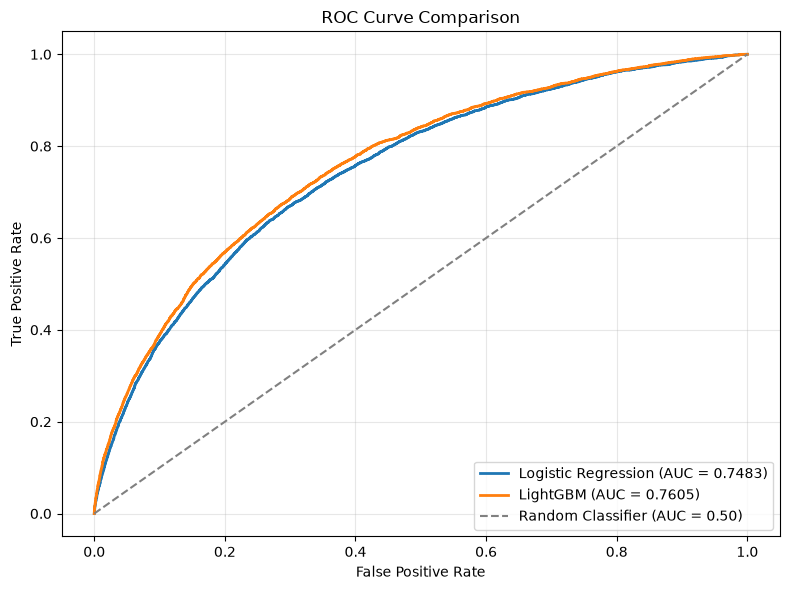

In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve coordinates
fpr_log, tpr_log, _ = roc_curve(y_valid, logistic_probs)
fpr_lgb, tpr_lgb, _ = roc_curve(y_valid, lgb_probs)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {logistic_auc:.4f})",
    linewidth=2
)

plt.plot(
    fpr_lgb,
    tpr_lgb,
    label=f"LightGBM (AUC = {lgb_auc:.4f})",
    linewidth=2
)

# Plot random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import numpy as np

# Initialize stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

# Perform cross-validation on the training set
for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train_lgb, y_train), start=1
):
    X_fold_train = X_train_lgb.iloc[train_idx]
    X_fold_valid = X_train_lgb.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[val_idx]

    # Initialize a fresh model for each fold
    model = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=290,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=50,
        colsample_bytree=0.8,
        subsample=0.8,
        subsample_freq=1,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1
    )

    # Train the model
    model.fit(X_fold_train, y_fold_train)

    # Predict validation probabilities
    fold_probs = model.predict_proba(X_fold_valid)[:, 1]

    # Calculate fold ROC-AUC
    fold_auc = roc_auc_score(y_fold_valid, fold_probs)
    cv_scores.append(fold_auc)

    print(f"Fold {fold}: AUC = {fold_auc:.4f}")

# Summarize cross-validation performance
print(f"\nMean CV AUC: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation: {np.std(cv_scores):.4f}")


Fold 1: AUC = 0.7560
Fold 2: AUC = 0.7560
Fold 3: AUC = 0.7583
Fold 4: AUC = 0.7583
Fold 5: AUC = 0.7539

Mean CV AUC: 0.7565
Standard Deviation: 0.0017


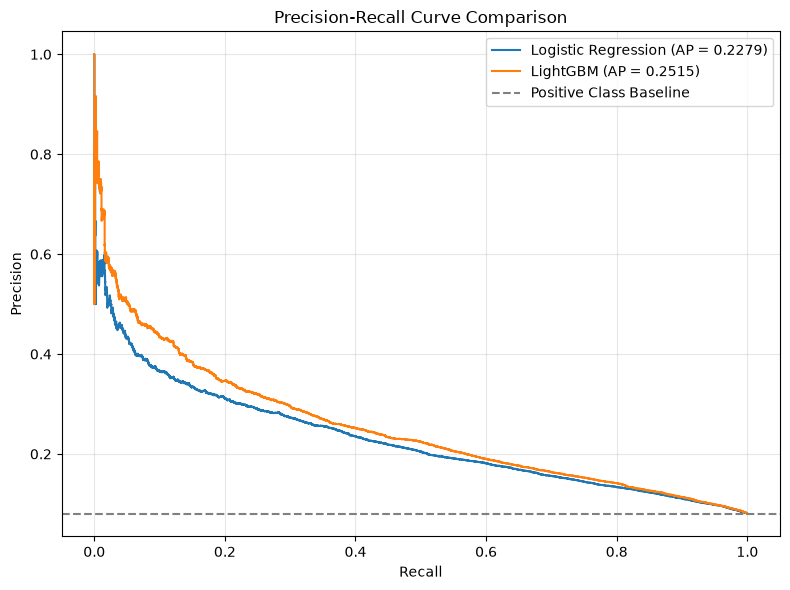

Logistic Regression AP: 0.2279
LightGBM AP: 0.2515


In [19]:

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Calculate precision-recall curves
precision_log, recall_log, _ = precision_recall_curve(
    y_valid, logistic_probs
)

precision_lgb, recall_lgb, _ = precision_recall_curve(
    y_valid, lgb_probs
)

# Calculate average precision scores
ap_log = average_precision_score(y_valid, logistic_probs)
ap_lgb = average_precision_score(y_valid, lgb_probs)

# Plot precision-recall curves
plt.figure(figsize=(8, 6))

plt.plot(
    recall_log,
    precision_log,
    label=f"Logistic Regression (AP = {ap_log:.4f})"
)

plt.plot(
    recall_lgb,
    precision_lgb,
    label=f"LightGBM (AP = {ap_lgb:.4f})"
)

# Plot the positive class prevalence baseline
plt.axhline(
    y=y_valid.mean(),
    color="gray",
    linestyle="--",
    label="Positive Class Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Logistic Regression AP: {ap_log:.4f}")
print(f"LightGBM AP: {ap_lgb:.4f}")


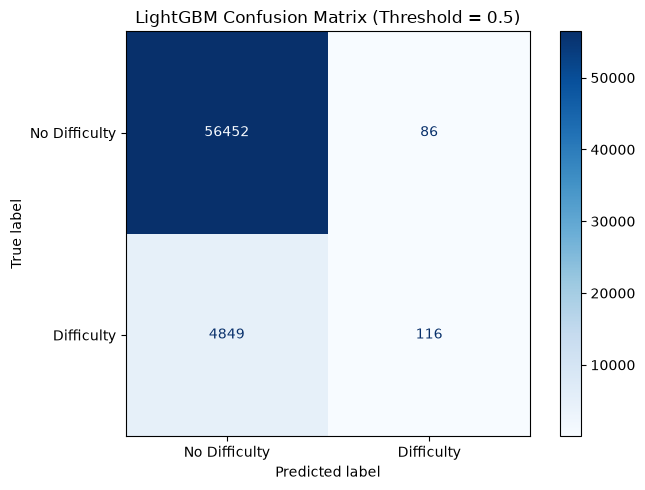

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.57      0.02      0.04      4965

    accuracy                           0.92     61503
   macro avg       0.75      0.51      0.50     61503
weighted avg       0.89      0.92      0.88     61503



In [20]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Convert predicted probabilities into binary predictions
threshold = 0.5
lgb_predictions = (lgb_probs >= threshold).astype(int)

# Calculate the confusion matrix
cm = confusion_matrix(y_valid, lgb_predictions)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Difficulty", "Difficulty"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("LightGBM Confusion Matrix (Threshold = 0.5)")
plt.tight_layout()
plt.show()

# Display classification metrics
print("Classification Report:")
print(classification_report(y_valid, lgb_predictions))


In [21]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Define classification thresholds
thresholds = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]

results = []

# Evaluate classification metrics at different thresholds
for threshold in thresholds:
    predictions = (lgb_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, predictions, zero_division=0
        )
    })

# Display threshold comparison
threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.05,0.1308,0.8324,0.2261
1,0.10,0.1926,0.5909,0.2905
2,0.15,0.2462,0.4175,0.3097
3,0.20,0.2963,0.2995,0.2979
4,0.30,0.3857,0.1458,0.2116
5,0.50,0.5743,0.0234,0.0449


,Feature,Importance
41,EXT_SOURCE_3,51648.926601
40,EXT_SOURCE_2,44160.372678
38,ORGANIZATION_TYPE,21188.887383
39,EXT_SOURCE_1,17037.187384
6,AMT_CREDIT,7529.203589
15,DAYS_BIRTH,6724.823668
8,AMT_GOODS_PRICE,6463.800896
26,OCCUPATION_TYPE,6382.263272
7,AMT_ANNUITY,6017.281539
16,DAYS_EMPLOYED,5603.799965


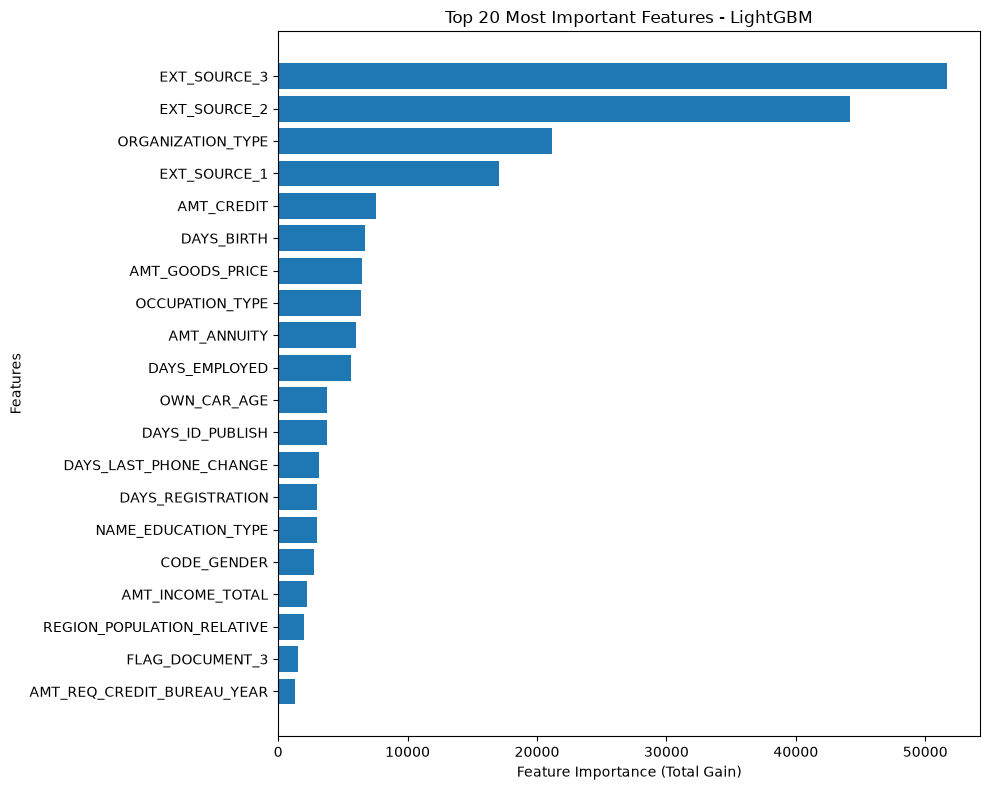

In [22]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance based on total split gain
feature_importance = pd.DataFrame({
    "Feature": lgb_model.booster_.feature_name(),
    "Importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    )
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 20 most important features
display(feature_importance.head(20))

# Plot the top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance (Total Gain)")
plt.ylabel("Features")
plt.title("Top 20 Most Important Features - LightGBM")

plt.tight_layout()
plt.show()


In [23]:

%pip install shap


Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


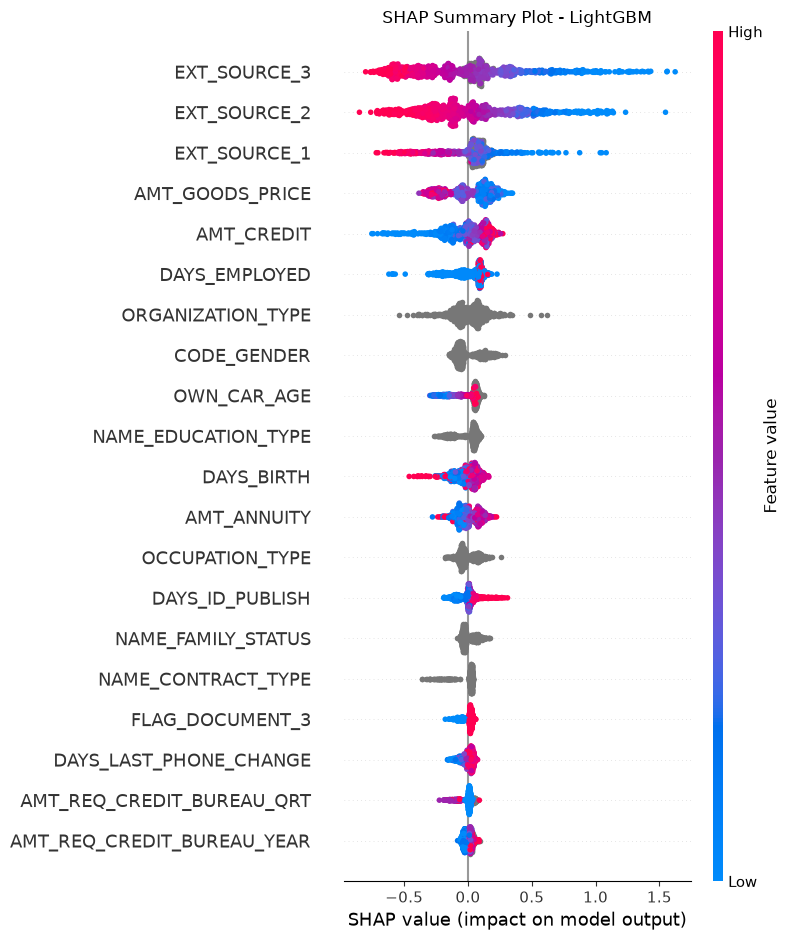

In [24]:

import shap
import matplotlib.pyplot as plt

# Select a sample to reduce computation time
X_shap = X_valid_lgb.sample(
    n=1000,
    random_state=42
)

# Initialize the SHAP TreeExplainer
explainer = shap.TreeExplainer(lgb_model)

# Calculate SHAP values
shap_values = explainer(X_shap)

# Select positive-class SHAP values if needed
if len(shap_values.values.shape) == 3:
    shap_values = shap_values[:, :, 1]

# Generate SHAP summary plot
shap.summary_plot(
    shap_values.values,
    X_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - LightGBM")
plt.tight_layout()
plt.show()


In [25]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import time

# Define the parameter search space
param_grid = {
    "num_leaves": [15, 31, 63],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_samples": [30, 50, 100],
    "reg_lambda": [0.1, 1.0, 5.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

# Initialize the LightGBM classifier
base_lgb = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=290,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Initialize randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_grid,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Run hyperparameter tuning
start_time = time.time()

random_search.fit(X_train_lgb, y_train)

tuning_time = time.time() - start_time

# Retrieve the best model
best_lgb_model = random_search.best_estimator_

# Evaluate the tuned model on the validation set
tuned_probs = best_lgb_model.predict_proba(
    X_valid_lgb
)[:, 1]

tuned_auc = roc_auc_score(y_valid, tuned_probs)

print(f"\nTuning time: {tuning_time:.2f} seconds")
print(f"Best CV AUC: {random_search.best_score_:.4f}")
print("Best parameters:", random_search.best_params_)
print(f"Original LightGBM AUC: {lgb_auc:.4f}")
print(f"Tuned LightGBM AUC: {tuned_auc:.4f}")
print(f"AUC difference: {tuned_auc - lgb_auc:+.4f}")


Fitting 3 folds for each of 12 candidates, totalling 36 fits

Tuning time: 141.40 seconds
Best CV AUC: 0.7554
Best parameters: {'reg_lambda': 0.1, 'num_leaves': 15, 'min_child_samples': 100, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Original LightGBM AUC: 0.7605
Tuned LightGBM AUC: 0.7606
AUC difference: +0.0001


In [26]:

import pandas as pd

# Create a model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM",
        "Tuned LightGBM"
    ],
    "Validation ROC-AUC": [
        logistic_auc,
        lgb_auc,
        tuned_auc
    ],
    "Validation Average Precision": [
        ap_log,
        ap_lgb,
        None
    ]
})

# Calculate average precision for the tuned model
from sklearn.metrics import average_precision_score

model_comparison.loc[
    model_comparison["Model"] == "Tuned LightGBM",
    "Validation Average Precision"
] = average_precision_score(y_valid, tuned_probs)

# Sort models by ROC-AUC
model_comparison = model_comparison.sort_values(
    by="Validation ROC-AUC",
    ascending=False
)

display(model_comparison.round(4))


,Model,Validation ROC-AUC,Validation Average Precision
2,Tuned LightGBM,0.7606,0.2503
1,LightGBM,0.7605,0.2515
0,Logistic Regression,0.7483,0.2279


In [27]:

%pip install seaborn


Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


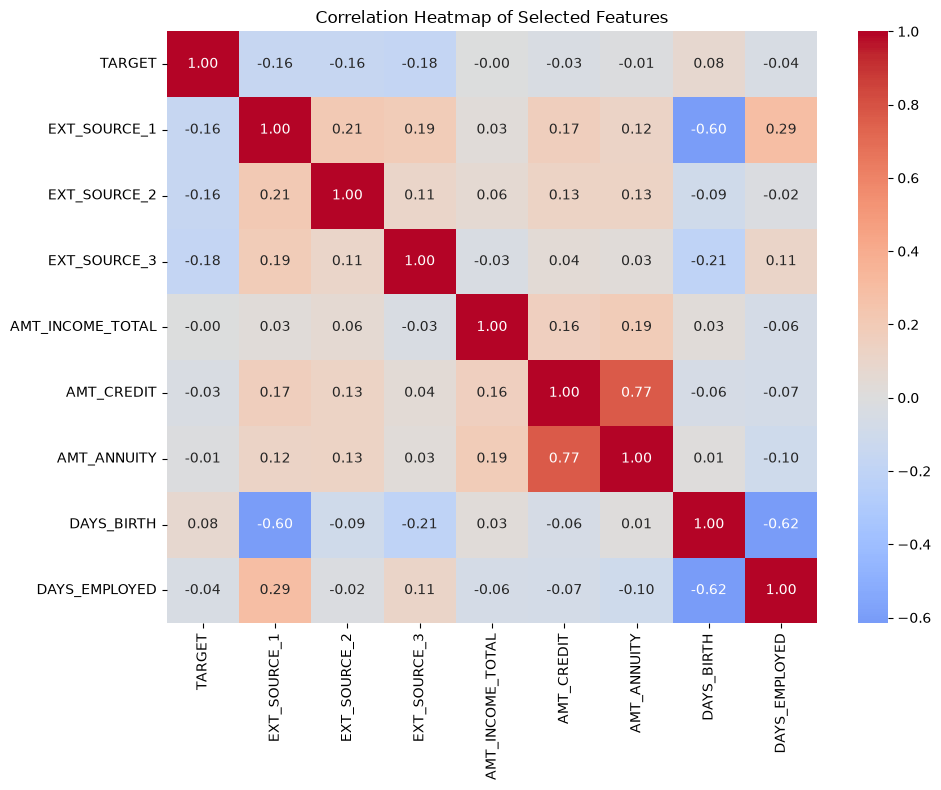

In [28]:

import seaborn as sns
import matplotlib.pyplot as plt

# Select relevant numerical features
selected_features = [
    "TARGET",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

# Calculate the Pearson correlation matrix
correlation_matrix = train[selected_features].corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout()
plt.show()


In [29]:

from sklearn.metrics import roc_auc_score
import pandas as pd

# Generate training and validation predictions
train_probs = best_lgb_model.predict_proba(
    X_train_lgb
)[:, 1]

valid_probs = best_lgb_model.predict_proba(
    X_valid_lgb
)[:, 1]

# Calculate ROC-AUC scores
train_auc = roc_auc_score(y_train, train_probs)
valid_auc = roc_auc_score(y_valid, valid_probs)

# Summarize model generalization performance
generalization_results = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "ROC-AUC": [train_auc, valid_auc]
})

display(generalization_results.round(4))

print(f"Train-Validation AUC Gap: {train_auc - valid_auc:.4f}")


,Dataset,ROC-AUC
0,Training,0.7866
1,Validation,0.7606


Train-Validation AUC Gap: 0.0260


## Final Conclusion

### 1. Project Objective

This project developed and evaluated machine learning models to predict loan repayment difficulties using the Home Credit Default Risk dataset.

The primary objective was to compare a traditional Logistic Regression baseline with a Gradient Boosting model (LightGBM), using ROC-AUC as the main evaluation metric.

### 2. Key Findings

**Model Performance**

- Logistic Regression achieved a validation ROC-AUC of 0.7483.
- LightGBM improved the validation ROC-AUC to 0.7605.
- Hyperparameter tuning resulted in a marginal improvement to 0.7606.
- Five-fold cross-validation produced a mean ROC-AUC of 0.7565 with a standard deviation of 0.0017.

These results suggest that LightGBM provides better discriminatory performance than the linear baseline, although further hyperparameter tuning produced limited additional improvement.

**Class Imbalance and Threshold Selection**

Only approximately 8.07% of applicants belonged to the positive class.

At the default classification threshold of 0.5, LightGBM achieved a recall of only 2.34%, demonstrating that a relatively strong ROC-AUC does not necessarily translate into effective positive-class identification at a fixed threshold.

Among the evaluated thresholds, 0.15 achieved the highest F1-score of 0.3097.

**Feature Importance and Model Interpretation**

External credit-related scores, particularly EXT_SOURCE_3, EXT_SOURCE_2, and EXT_SOURCE_1, were among the most influential predictors.

SHAP analysis indicated that lower external scores generally increased the model's predicted repayment difficulty risk.

**Generalization Performance**

The tuned LightGBM model achieved a training ROC-AUC of 0.7866 and a validation ROC-AUC of 0.7606.

The difference of 0.0260 suggests some degree of overfitting, although cross-validation results indicate relatively stable predictive performance.

### 3. Limitations

Several limitations should be acknowledged:

- The dataset is highly imbalanced, making threshold selection particularly important.
- Some features contain substantial proportions of missing values.
- The analysis primarily uses the main application dataset rather than incorporating all available relational tables.
- Hyperparameter tuning was conducted using a limited search space.
- The validation dataset was used during model development, so the reported results should not be interpreted as a completely independent final test evaluation.
- Model explanations identify predictive associations rather than causal relationships.

### 4. Future Improvements

Future work could incorporate additional information from the bureau, previous application, and repayment history tables.

Further improvements could include more extensive feature engineering, probability calibration, cost-sensitive threshold selection, and evaluation on a fully independent holdout dataset.

### 5. Overall Conclusion

LightGBM outperformed Logistic Regression in predicting loan repayment difficulties, achieving a validation ROC-AUC of 0.7606 after hyperparameter tuning.

The project demonstrates the effectiveness of gradient boosting for structured credit risk data while highlighting the importance of class imbalance, model interpretability, validation design, and appropriate decision thresholds.

In [30]:

from pathlib import Path

# Define the project directory
project_dir = Path.cwd().parent

# Use the existing outputs directory
results_dir = project_dir / "outputs"

# Ensure the directory exists
results_dir.mkdir(parents=True, exist_ok=True)

print("Project directory:", project_dir)
print("Results directory:", results_dir)


Project directory: /Users/xts/Desktop/Jeremy_Projects/gradient_boosting_project
Results directory: /Users/xts/Desktop/Jeremy_Projects/gradient_boosting_project/outputs


In [32]:

from pathlib import Path
import pandas as pd
import numpy as np

# Define the project output directory
project_dir = Path.cwd().parent
results_dir = project_dir / "outputs"
results_dir.mkdir(parents=True, exist_ok=True)

# Export model comparison
model_comparison.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

# Export cross-validation scores
pd.DataFrame({
    "Fold": range(1, len(cv_scores) + 1),
    "ROC_AUC": cv_scores
}).to_csv(
    results_dir / "cross_validation_scores.csv",
    index=False
)

# Export threshold analysis
threshold_results.to_csv(
    results_dir / "threshold_analysis.csv",
    index=False
)

# Export feature importance
feature_importance.to_csv(
    results_dir / "feature_importance.csv",
    index=False
)

# Export model summary
summary = f"""HOME CREDIT DEFAULT RISK - MODEL RESULTS

Logistic Regression AUC: {logistic_auc:.4f}
LightGBM AUC: {lgb_auc:.4f}
Tuned LightGBM AUC: {tuned_auc:.4f}

Mean Cross-Validation AUC: {np.mean(cv_scores):.4f}
CV Standard Deviation: {np.std(cv_scores):.4f}

Training AUC: {train_auc:.4f}
Validation AUC: {valid_auc:.4f}
AUC Gap: {train_auc - valid_auc:.4f}

Best Hyperparameters:
{random_search.best_params_}
"""

(results_dir / "model_summary.txt").write_text(
    summary,
    encoding="utf-8"
)

# Verify exported files
print("Results saved successfully!")
print("Output directory:", results_dir)

for file in sorted(results_dir.iterdir()):
    print(file.name)


Results saved successfully!
Output directory: /Users/xts/Desktop/Jeremy_Projects/gradient_boosting_project/outputs
cross_validation_scores.csv
feature_importance.csv
model_comparison.csv
model_summary.txt
threshold_analysis.csv


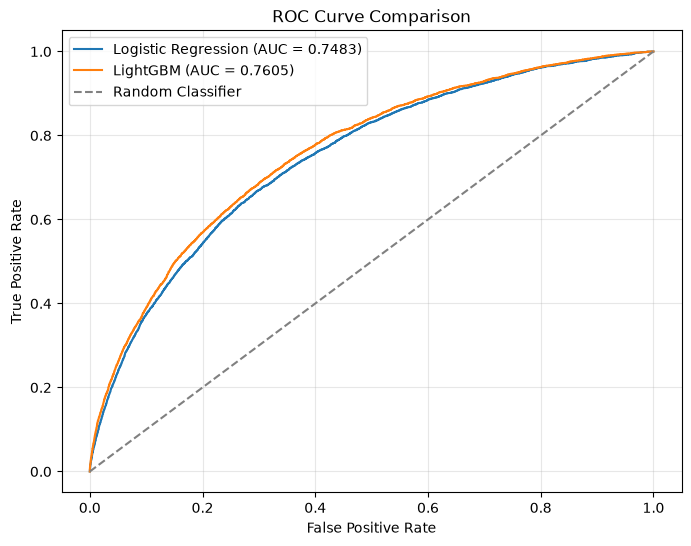

Saved: /Users/xts/Desktop/Jeremy_Projects/gradient_boosting_project/outputs/figures/roc_curve.png


In [33]:

from pathlib import Path
import matplotlib.pyplot as plt

# Create the figures directory
figures_dir = Path.cwd().parent / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Plot ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {logistic_auc:.4f})"
)

ax.plot(
    fpr_lgb,
    tpr_lgb,
    label=f"LightGBM (AUC = {lgb_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison")
ax.legend()
ax.grid(alpha=0.3)

# Save the figure
fig.savefig(
    figures_dir / "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figures_dir / "roc_curve.png")


In [34]:

import matplotlib.pyplot as plt
import seaborn as sns
import shap
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

# Define the figures directory
figures_dir = Path.cwd().parent / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Target distribution
fig, ax = plt.subplots(figsize=(7, 5))
train["TARGET"].value_counts().sort_index().plot(
    kind="bar", ax=ax
)
ax.set_title("Target Distribution")
ax.set_xlabel("Target")
ax.set_ylabel("Number of Applicants")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figures_dir / "target_distribution.png", dpi=300)
plt.close(fig)

# 2. Missing values
missing_pct = train.isna().mean().mul(100).nlargest(20)

fig, ax = plt.subplots(figsize=(10, 7))
missing_pct.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 20 Features by Missing Percentage")
ax.set_xlabel("Missing Values (%)")
fig.tight_layout()
fig.savefig(figures_dir / "missing_values.png", dpi=300)
plt.close(fig)

# 3. Correlation heatmap
selected_features = [
    "TARGET", "EXT_SOURCE_1", "EXT_SOURCE_2",
    "EXT_SOURCE_3", "AMT_INCOME_TOTAL",
    "AMT_CREDIT", "AMT_ANNUITY",
    "DAYS_BIRTH", "DAYS_EMPLOYED"
]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    train[selected_features].corr(),
    annot=True, fmt=".2f", cmap="coolwarm",
    center=0, ax=ax
)
ax.set_title("Correlation Heatmap")
fig.tight_layout()
fig.savefig(figures_dir / "correlation_heatmap.png", dpi=300)
plt.close(fig)

# 4. Precision-recall curves
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_log, precision_log, label=f"Logistic Regression (AP={ap_log:.4f})")
ax.plot(recall_lgb, precision_lgb, label=f"LightGBM (AP={ap_lgb:.4f})")
ax.axhline(y_valid.mean(), linestyle="--", color="gray",
           label="Positive Class Baseline")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve Comparison")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "precision_recall_curve.png", dpi=300)
plt.close(fig)

# 5. Confusion matrix
cm = confusion_matrix(y_valid, lgb_probs >= 0.5)
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(
    cm, display_labels=["No Difficulty", "Difficulty"]
).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("LightGBM Confusion Matrix (Threshold = 0.5)")
fig.tight_layout()
fig.savefig(figures_dir / "confusion_matrix.png", dpi=300)
plt.close(fig)

# 6. Feature importance
top_features = feature_importance.head(20).sort_values("Importance")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_features["Feature"], top_features["Importance"])
ax.set_xlabel("Total Gain")
ax.set_title("Top 20 LightGBM Features")
fig.tight_layout()
fig.savefig(figures_dir / "feature_importance.png", dpi=300)
plt.close(fig)

# 7. SHAP summary plot
X_shap = X_valid_lgb.sample(n=1000, random_state=42)
explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer(X_shap)

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(
    shap_values.values,
    X_shap,
    max_display=20,
    show=False
)
plt.title("SHAP Summary Plot - LightGBM")
plt.tight_layout()
plt.savefig(
    figures_dir / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Verify exported figures
print("Figures exported successfully:")
for file in sorted(figures_dir.glob("*.png")):
    print(file.name)


Figures exported successfully:
confusion_matrix.png
correlation_heatmap.png
feature_importance.png
missing_values.png
precision_recall_curve.png
roc_curve.png
shap_summary.png
target_distribution.png
